# SVM: margen lineal y aproximación RBF

Esta notebook entrena un detector binario de sirenas: **EMERGENCY** frente a **NON_EMERGENCY**.
Forma parte de la comparación de cinco modelos definida en el proyecto. Sus entradas son las
21 características de cada segmento preparado; sus salidas incluyen un modelo exportado y
evidencia de desarrollo reproducible.

La selección utiliza AudioSet-EV v2, sireNNet y A3Siren-Recordings. LSSiren permanece reservado
para una evaluación predictiva posterior. Las etiquetas heredadas de archivos o tracks son
supervisión débil a nivel de ventana y las ventanas solapadas no son observaciones independientes.


## 1. Insumos y configuración

Adjunta un paquete completo de preparación v3 o v2. Si hay varios, selecciona `prepared_zip` o `prepared_root`. El ZIP de reportes no es un insumo de entrenamiento. La semilla es 42 y el presupuesto se fija antes de consultar la validación.


In [1]:
CFG = {
    "seed": 42,
    "prepared_root": None,
    "search_roots": ["/kaggle/input"],
    "output_base": "/kaggle/working/entrenamiento",
    "metadata_file": "metadata/metadata_segments.csv",
    "file_metadata_file": None,
    "preparation_config": "config/preparation_config.json",
    "split_files": {
        "train": "splits/train.csv",
        "validation": "splits/validation.csv",
        "generalization": "splits/generalization.csv",
    },
    "column_map": {},
    "label_map": {"NON_EMERGENCY": 0, "EMERGENCY": 1},
    "dataset_aliases": {
        "AudioSet-EV": "AudioSet-EV v2",
        "audioset-ev": "AudioSet-EV v2",
        "audioset_ev": "AudioSet-EV v2",
        "sirennet": "sireNNet",
        "SireNNet": "sireNNet",
        "a3s-rec": "A3Siren-Recordings",
        "A3Siren": "A3Siren-Recordings",
        "lssiren": "LSSiren",
    },
    "development_corpora": ["AudioSet-EV v2", "sireNNet", "A3Siren-Recordings"],
    "holdout_corpus": "LSSiren",
    "additional_group_columns": [
        "source_video_id",
        "original_recording_id",
        "augmentation_parent_id",
    ],
    "require_original_group_column": None,
    "cv_folds": 3,
    "target_recall": 0.9,
    "target_fpr": 0.1,
    "bootstrap_repeats": 500,
    "cpu_workers": 2,
    "latency_warmup": 20,
    "latency_repeats": 100,
    "throughput_batch": 2048,
    "feature_files": ["features/acoustic_features.csv", "features/mfcc_features.csv"],
    "features_are_unscaled": True,
    "feature_columns": [
        "rms",
        "zcr",
        "dominant_frequency",
        "spectral_centroid",
        "spectral_bandwidth",
        "spectral_rolloff",
        "spectral_flux",
        "spectral_flatness",
        "mfcc_1",
        "mfcc_2",
        "mfcc_3",
        "mfcc_4",
        "mfcc_5",
        "mfcc_6",
        "mfcc_7",
        "mfcc_8",
        "mfcc_9",
        "mfcc_10",
        "mfcc_11",
        "mfcc_12",
        "mfcc_13",
    ],
    "feature_column_map": {
        "dominant_frequency_hz": "dominant_frequency",
        "spectral_centroid_hz": "spectral_centroid",
        "spectral_bandwidth_hz": "spectral_bandwidth",
        "spectral_rolloff_hz": "spectral_rolloff",
    },
    "max_iter": 20000,
    "model_name": "03_svm",
    "display_name": "SVM lineal y aproximación RBF",
    "model_kind": "svm",
    "candidates": [
        {"kernel": "linear", "C": 0.1},
        {"kernel": "linear", "C": 1.0},
        {
            "kernel": "nystroem_rbf",
            "C": 1.0,
            "gamma": 0.047619047619047616,
            "n_components": 256,
        },
    ],
    "prepared_zip": None,
    "prepared_cache": "/kaggle/working/prepared_cache",
    "unzip_reserve_gib": 2.0,
    "heartbeat_seconds": 30,
}

In [2]:
def validate_training_config(config):
    for key in [
        "cv_folds",
        "cpu_workers",
        "bootstrap_repeats",
        "latency_repeats",
        "latency_warmup",
    ]:
        if not isinstance(config[key], int) or config[key] < 1:
            raise ValueError(f"{key} debe ser un entero positivo.")
    if config["cv_folds"] < 2 or not config["candidates"]:
        raise ValueError("Se requieren al menos dos folds y un candidato.")
    if not 0 < config["target_recall"] <= 1 or not 0 < config["target_fpr"] <= 1:
        raise ValueError("Metas de recall/FPR fuera de rango.")
    if config["label_map"] != {"NON_EMERGENCY": 0, "EMERGENCY": 1}:
        raise ValueError("EMERGENCY debe ser la clase positiva, codificada como 1.")
    if config["model_kind"] in ["cnn", "resnet"]:
        for key in [
            "batch_size",
            "max_epochs",
            "patience",
            "max_gpus",
            "normalization_chunk",
        ]:
            if not isinstance(config[key], int) or config[key] < 1:
                raise ValueError(f"{key} debe ser un entero positivo.")
        if config["loader_workers"] != 0:
            raise ValueError(
                "Esta versión autocontenida utiliza loader_workers=0 para evitar procesos de notebook."
            )
        if (
            config["model_kind"] == "resnet"
            and config["max_epochs"] <= config["head_warmup_epochs"]
        ):
            raise ValueError(
                "max_epochs debe permitir al menos una época de ajuste fino."
            )

In [3]:
validate_training_config(CFG)

### Dependencias

Se utilizan las bibliotecas disponibles en Kaggle. Las versiones efectivas y el hardware se registran con cada ejecución; no se actualizan paquetes automáticamente.


In [4]:
import os
import sys
import json
import time
import hashlib
import platform
import shutil
import random
import warnings
import subprocess
import gc
import zipfile
import stat

from pathlib import Path

from datetime import datetime, timezone

from importlib.metadata import version, PackageNotFoundError

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
)

from sklearn.exceptions import ConvergenceWarning

try:
    from IPython.display import display
except ImportError:

    def display(value):
        print(value)

### Salida y trazabilidad

Cada ejecución escribe en una carpeta propia de `/kaggle/working`. Las fuentes montadas en `/kaggle/input` permanecen sin modificaciones.


In [5]:
def jsonable(x):
    if isinstance(x, np.generic):
        return x.item()
    if isinstance(x, np.ndarray):
        return x.tolist()
    if isinstance(x, Path):
        return str(x)
    raise TypeError(type(x).__name__)

In [6]:
def write_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(
        json.dumps(obj, ensure_ascii=False, indent=2, default=jsonable),
        encoding="utf-8",
    )
    tmp.replace(path)

In [7]:
def sha_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

In [8]:
def save_table(name, rows):
    data = rows if isinstance(rows, pd.DataFrame) else pd.DataFrame(rows)
    data.to_csv(OUT / "tables" / name, index=False)
    return data

In [9]:
def fail(message):
    write_json(
        OUT / "reports" / "failure.json", {"status": "BLOCKED", "message": str(message)}
    )
    import zipfile

    diagnostic = OUT.parent / (OUT.name + "_diagnostico.zip")
    with zipfile.ZipFile(diagnostic, "w", zipfile.ZIP_DEFLATED) as z:
        for folder in ["config", "reports", "tables"]:
            for p in (OUT / folder).rglob("*"):
                if p.is_file():
                    z.write(p, str(p.relative_to(OUT)))
    print("Diagnóstico:", diagnostic)
    raise ValueError(message)

In [10]:
def environment():
    packages = {}
    for name in [
        "numpy",
        "pandas",
        "scikit-learn",
        "scipy",
        "matplotlib",
        "joblib",
        "torch",
        "torchvision",
    ]:
        try:
            packages[name] = version(name)
        except PackageNotFoundError:
            packages[name] = None
    try:
        gpu = subprocess.run(
            [
                "nvidia-smi",
                "--query-gpu=name,memory.total,driver_version",
                "--format=csv,noheader",
            ],
            capture_output=True,
            text=True,
            timeout=10,
        ).stdout.strip()
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = "No detectada"
    try:
        ram = (
            int(
                next(
                    line.split()[1]
                    for line in Path("/proc/meminfo").read_text().splitlines()
                    if line.startswith("MemTotal:")
                )
            )
            * 1024
        )
    except Exception:
        ram = None
    return {
        "python": sys.version,
        "platform": platform.platform(),
        "packages": packages,
        "cpu_count": os.cpu_count(),
        "ram_bytes": ram,
        "gpu_nvidia_smi": gpu,
        "disk_free_bytes": shutil.disk_usage(OUT).free,
    }

In [11]:
random.seed(CFG["seed"])

np.random.seed(CFG["seed"])

OUTPUT_BASE = Path(CFG["output_base"]).resolve()

if str(OUTPUT_BASE).startswith("/kaggle/input"):
    raise ValueError("La salida nunca puede ubicarse dentro de /kaggle/input.")

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = OUTPUT_BASE / CFG["model_name"] / RUN_ID

for folder in [
    "config",
    "tables",
    "figures",
    "reports",
    "models",
    "predictions",
    "checkpoints",
    "logs",
]:
    (OUT / folder).mkdir(parents=True, exist_ok=True)

START_TIME = time.perf_counter()

write_json(OUT / "config" / "training_config.json", CFG)

ENV = environment()

write_json(OUT / "reports" / "environment.json", ENV)

display(
    pd.DataFrame(
        [
            {
                "modelo": CFG["model_name"],
                "salida": str(OUT),
                "CPU": ENV["cpu_count"],
                "GPU": ENV["gpu_nvidia_smi"],
            }
        ]
    )
)

RUNTIME_COSTS = []

,modelo,salida,CPU,GPU
0,03_svm,/kaggle/working/entrenamiento/03_svm/20261012T...,4,No detectada


In [12]:
def record_cost(phase, started):
    """Registra tiempo de pared; no confunde preparación con inferencia."""
    RUNTIME_COSTS.append({"phase": phase, "seconds": time.perf_counter() - started})

In [13]:
def safe_member_path(name):
    """Comprueba las rutas relativas antes de leer o extraer un artefacto."""
    from pathlib import PurePosixPath

    parts = PurePosixPath(name).parts
    if not parts or PurePosixPath(name).is_absolute() or ".." in parts or "\\" in name:
        raise ValueError(f"Ruta relativa inválida: {name}")
    return name

In [14]:
def atomic_zip(destination, entries):
    """Publica un ZIP completo únicamente después de verificar su CRC."""
    destination = Path(destination)
    temporary = destination.with_suffix(destination.suffix + ".partial")
    try:
        with zipfile.ZipFile(
            temporary, "w", zipfile.ZIP_DEFLATED, allowZip64=True
        ) as archive:
            for path, name in entries:
                archive.write(path, safe_member_path(name))
        with zipfile.ZipFile(temporary) as archive:
            invalid = archive.testzip()
            if invalid:
                raise ValueError(f"CRC inválido: {invalid}")
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
    return destination

### Registro de etapas

El registro de consola se complementa con `logs/training.log` y `logs/events.jsonl`. Un error guarda su traceback y un ZIP diagnóstico; los checkpoints contienen pesos y no garantizan una reanudación exacta del optimizador.


In [15]:
import logging
import traceback
import threading

from contextlib import contextmanager

try:
    from tqdm.auto import tqdm
except ImportError:

    class tqdm:
        def __init__(self, iterable=None, total=None, **kwargs):
            self.iterable = iterable

        def __iter__(self):
            return iter(self.iterable)

        def update(self, *args, **kwargs):
            pass

        def set_postfix(self, *args, **kwargs):
            pass

        def close(self):
            pass


try:
    import psutil
except ImportError:
    psutil = None

LOG_DIR = OUT / "logs"

LOG_DIR.mkdir(exist_ok=True)

LOGGER = logging.getLogger("doppler." + str(OUT))

LOGGER.setLevel(logging.INFO)

LOGGER.propagate = False

for h in LOGGER.handlers[:]:
    h.close()
    LOGGER.removeHandler(h)

handler = logging.FileHandler(LOG_DIR / "training.log", encoding="utf-8")

handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))

LOGGER.addHandler(handler)

console = logging.StreamHandler(sys.stdout)

console.setFormatter(logging.Formatter("%(asctime)s | %(message)s", datefmt="%H:%M:%S"))

LOGGER.addHandler(console)

In [16]:
def resource_snapshot():
    if psutil:
        return {"rss_mib": psutil.Process().memory_info().rss / 1024**2}
    return {}

In [17]:
def event(kind, console=True, **fields):
    record = {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "event": kind,
        **resource_snapshot(),
        **fields,
    }
    with open(LOG_DIR / "events.jsonl", "a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False, default=str) + "\n")
    if console:
        LOGGER.info(
            "%s | %s",
            kind,
            " | ".join(
                f"{k}={v:.5g}" if isinstance(v, float) else f"{k}={v}"
                for k, v in fields.items()
            ),
        )

In [18]:
def diagnostic_bundle():
    import zipfile

    target = OUT.parent / (OUT.name + "_diagnostico.zip")
    with zipfile.ZipFile(target, "w", zipfile.ZIP_DEFLATED) as z:
        for folder in ["config", "reports", "tables", "logs", "metadata"]:
            for p in (OUT / folder).rglob("*"):
                if p.is_file():
                    z.write(p, str(p.relative_to(OUT)))
    return str(target)

In [19]:
@contextmanager
def stage_guard(name):
    tick = time.perf_counter()
    event("stage_start", stage=name)
    try:
        yield
    except Exception as exc:
        error = traceback.format_exc()
        (LOG_DIR / "traceback.txt").write_text(error, encoding="utf-8")
        event(
            "stage_failed",
            stage=name,
            error=str(exc),
            seconds=time.perf_counter() - tick,
        )
        write_json(
            OUT / "reports/run_status.json",
            {"status": "FAILED", "stage": name, "error": str(exc)},
        )
        try:
            print("Diagnóstico guardado:", diagnostic_bundle())
        except Exception as diag_exc:
            print("No se pudo comprimir el diagnóstico:", diag_exc)
        raise
    else:
        event("stage_end", stage=name, seconds=time.perf_counter() - tick)

In [20]:
@contextmanager
def heartbeat(phase, **fields):
    stop = threading.Event()
    tick = time.perf_counter()

    def worker():
        while not stop.wait(CFG.get("heartbeat_seconds", 30)):
            event(
                "fit_running",
                phase=phase,
                elapsed_seconds=time.perf_counter() - tick,
                **fields,
            )

    thread = threading.Thread(target=worker, daemon=True)
    thread.start()
    try:
        yield
    finally:
        stop.set()
        thread.join(timeout=1)

In [21]:
write_json(OUT / "reports/run_status.json", {"status": "RUNNING"})

event("run_start", model=CFG.get("model_name", "preparation"), output=str(OUT))

07:29:34 | run_start | model=03_svm | output=/kaggle/working/entrenamiento/03_svm/20261012T072934_078808Z


## 2. Lectura y contrato de datos

Las uniones utilizan `segment_id`, nunca la posición de una fila. Se comprueban cobertura de particiones, etiquetas y ambigüedades del paquete. La extracción y su caché verifican contenido.


In [22]:
with stage_guard("data_adapters"):
    ALIASES = {
        "segment_id": ["segment_id", "segment_uid"],
        "dataset": ["dataset", "corpus", "dataset_name"],
        "file_id": ["file_id", "source_file_id"],
        "track_id": ["track_id", "source_track_id"],
        "canonical_label": ["canonical_label", "label_binary", "target_label"],
        "original_label": ["original_label", "label_original"],
        "split": ["split", "partition", "subset"],
        "sha256": ["sha256", "source_sha256"],
        "original_path": ["original_path", "source_path"],
        "representation_path": [
            "representation_path",
            "path_to_representation",
            "logmel_path",
            "spectrogram_path",
        ],
    }

07:29:34 | stage_start | stage=data_adapters
07:29:34 | stage_end | stage=data_adapters | seconds=0.0023747


In [23]:
def canonicalize(df):
    # Las equivalencias adicionales se especifican como {columna_original: columna_canónica}.
    df = df.rename(columns=CFG["column_map"]).copy()
    if df.columns.duplicated().any():
        fail("El mapeo de columnas crea nombres duplicados.")
    for canonical, variants in ALIASES.items():
        found = [c for c in variants if c in df]
        if canonical not in df and len(found) == 1:
            df = df.rename(columns={found[0]: canonical})
        elif canonical not in df and len(found) > 1:
            fail(f"Columnas ambiguas para {canonical}: {found}")
    return df

In [24]:
def read_csv(path):
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    return canonicalize(df)

In [25]:
def zip_contract(path):
    required = [
        "features/acoustic_features.csv",
        "features/mfcc_features.csv",
        "splits/train.csv",
        "splits/validation.csv",
        "splits/generalization.csv",
        "config/preparation_config.json",
    ]
    try:
        with zipfile.ZipFile(path) as archive:
            names = set(archive.namelist())
            suffix = "metadata/metadata_segments.csv"
            roots = [name[: -len(suffix)] for name in names if name.endswith(suffix)]
            roots = [
                root for root in roots if all(root + name in names for name in required)
            ]
            if len(roots) == 1:
                return roots[0]
    except (OSError, zipfile.BadZipFile):
        return None
    return None

In [26]:
def unpack_prepared(path, prefix):
    """La caché comprueba contenido, incluso si una alteración conserva el tamaño."""
    started = time.perf_counter()
    with heartbeat("zip_sha256"):
        fingerprint = sha_file(path)
    cache = Path(CFG["prepared_cache"]).resolve()
    if cache == Path("/kaggle/input") or Path("/kaggle/input") in cache.parents:
        fail("prepared_cache debe estar fuera de /kaggle/input.")
    branch = "deep" if CFG["model_kind"] in ["cnn", "resnet"] else "tabular"
    cache.mkdir(parents=True, exist_ok=True)
    destination = cache / (fingerprint[:20] + "_" + branch)
    marker = destination / "EXTRACTION_COMPLETE.json"
    if marker.is_file():
        saved = json.loads(marker.read_text())
        valid = saved.get("zip_sha256") == fingerprint
        for name, expected in saved.get("members", {}).items():
            target = destination / safe_member_path(name)
            valid = valid and target.is_file() and sha_file(target) == expected
        if not valid or not saved.get("members"):
            fail("La caché cambió o está incompleta. Usa otra prepared_cache.")
        record_cost("verificacion_cache_zip", started)
        return destination
    if destination.exists():
        fail("Existe una extracción parcial. Usa otra prepared_cache.")
    with zipfile.ZipFile(path) as archive:
        chosen, seen = [], set()
        for info in archive.infolist():
            if info.is_dir() or not info.filename.startswith(prefix):
                continue
            name = safe_member_path(info.filename[len(prefix) :])
            if stat.S_ISLNK(info.external_attr >> 16) or name in seen:
                fail("El ZIP contiene enlaces simbólicos o nombres repetidos.")
            seen.add(name)
            if name.startswith("_staging/"):
                continue
            if name.startswith("representations/"):
                if (
                    branch == "tabular"
                    or name == "representations/logmel/generalization.npy"
                ):
                    continue
            chosen.append((info, name))
        needed = sum(info.file_size for info, _ in chosen)
        if shutil.disk_usage(cache).free < needed + CFG["unzip_reserve_gib"] * 1024**3:
            fail("Espacio insuficiente para extraer el paquete.")
        destination.mkdir()
        members = {}
        for info, name in tqdm(
            chosen, desc="Extraer insumos " + branch, unit="archivo"
        ):
            target = destination / name
            target.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(info) as source, target.open("wb") as output:
                shutil.copyfileobj(source, output, 1024 * 1024)
            members[name] = sha_file(target)
        write_json(marker, {"zip_sha256": fingerprint, "members": members})
    record_cost("extraccion_zip", started)
    return destination

In [27]:
def find_root():
    """Una sola exploración; las rutas explícitas tienen prioridad."""
    started = time.perf_counter()
    if CFG["prepared_root"] and CFG["prepared_zip"]:
        fail("Configura prepared_root o prepared_zip, no ambos.")
    if CFG["prepared_root"]:
        root = Path(CFG["prepared_root"]).resolve()
        if not (root / "metadata/metadata_segments.csv").is_file():
            fail(f"Falta el manifiesto de preparación en {root}.")
        record_cost("descubrimiento_insumos", started)
        return root
    if CFG["prepared_zip"]:
        path = Path(CFG["prepared_zip"])
        prefix = zip_contract(path)
        if prefix is None:
            fail(f"No es un paquete completo: {path}")
        record_cost("descubrimiento_insumos", started)
        return unpack_prepared(path, prefix)
    roots, archives = set(), []
    for base in CFG["search_roots"]:
        base = Path(base)
        if not base.exists():
            continue
        for directory, _, filenames in os.walk(base):
            directory = Path(directory)
            if directory.name == "metadata" and "metadata_segments.csv" in filenames:
                root = directory.parent
                if (root / "features/acoustic_features.csv").is_file():
                    roots.add(root)
            archives.extend(
                directory / name for name in filenames if name.lower().endswith(".zip")
            )
    candidates = [(path, zip_contract(path)) for path in sorted(set(archives))]
    candidates = [(path, prefix) for path, prefix in candidates if prefix is not None]
    if len(roots) + len(candidates) != 1:
        fail(
            "Se requiere un único paquete completo. Fija prepared_root o prepared_zip."
        )
    record_cost("descubrimiento_insumos", started)
    if roots:
        return next(iter(roots))
    return unpack_prepared(*candidates[0])

In [28]:
def required_path(relative):
    p = Path(relative)
    p = p if p.is_absolute() else ROOT / p
    if not p.is_file():
        fail(f"Falta el insumo requerido: {p}. Adjunta las salidas de preparación.")
    key = p.relative_to(ROOT).as_posix() if p.is_relative_to(ROOT) else str(p)
    if key not in INPUT_HASHES:
        INPUT_HASHES[key] = sha_file(p)
    return p

In [29]:
def merge_by_segment(left, right, origin):
    if "segment_id" not in right:
        fail(f"{origin}: falta segment_id. No se permite unir por posición de fila.")
    if right.segment_id.duplicated().any():
        fail(f"{origin}: segment_id repetido.")
    common = [c for c in right if c in left and c != "segment_id"]
    indexed = right.set_index("segment_id")
    if not left.segment_id.isin(indexed.index).all():
        fail(f"{origin}: faltan segmentos del manifiesto.")
    for c in common:
        r = left.segment_id.map(indexed[c]).astype(str)
        left_values = left[c].astype(str)
        present = left_values.ne("") & r.ne("")
        mismatch = left_values.to_numpy() != r.to_numpy()
        if c in CFG.get("feature_columns", []):
            ln = pd.to_numeric(left_values, errors="coerce").to_numpy(dtype=float)
            rn = pd.to_numeric(r, errors="coerce").to_numpy(dtype=float)
            mismatch = ~(
                np.isfinite(ln)
                & np.isfinite(rn)
                & np.isclose(ln, rn, rtol=1e-6, atol=1e-8)
            )
        if (present.to_numpy() & mismatch).any():
            fail(
                f"{origin}: conflicto en la columna {c}. Corrige el contrato de entrada."
            )
        left[c] = np.where(left_values.eq(""), r, left_values)
    return left.merge(
        right.drop(columns=common), on="segment_id", how="left", validate="one_to_one"
    )

In [30]:
def read_manifest():
    m = read_csv(required_path(CFG["metadata_file"]))
    # Puede completar metadata de archivo cuando la tabla de segmentos no repite esos atributos.
    if CFG["file_metadata_file"]:
        source = read_csv(required_path(CFG["file_metadata_file"]))
        keys = ["dataset", "file_id"]
        if not all(c in m and c in source for c in keys):
            fail("metadata de archivo requiere dataset y file_id en ambas tablas.")
        if source.duplicated(keys).any():
            fail("metadata de archivo contiene claves dataset+file_id repetidas.")
        idx = pd.MultiIndex.from_frame(m[keys])
        source = source.set_index(keys)
        if not idx.isin(source.index).all():
            fail("metadata de archivo no cubre todos los segmentos.")
        for c in source:
            if c in ["segment_id", "split", "start_time", "end_time"]:
                continue
            values = source[c].reindex(idx).to_numpy()
            if c not in m:
                m[c] = values
            else:
                conflict = m[c].ne("") & (values != "") & m[c].ne(values)
                if conflict.any():
                    fail(f"Metadata de archivo y segmento discrepan en {c}.")
                m[c] = np.where(m[c].eq(""), values, m[c])
    for c in ["segment_id", "dataset", "file_id", "canonical_label"]:
        if c not in m or m[c].eq("").any():
            fail(f"El manifiesto requiere {c} completo.")
    if m.segment_id.duplicated().any():
        fail("Hay segment_id duplicados.")
    assigned = []
    for split, filename in CFG["split_files"].items():
        s = read_csv(required_path(filename))
        if "segment_id" in s:
            keys = ["segment_id"]
        elif all(c in s for c in ["dataset", "file_id"]):
            keys = ["dataset", "file_id"]
        elif all(c in s for c in ["dataset", "track_id"]) and "track_id" in m:
            keys = ["dataset", "track_id"]
        else:
            fail(f"{filename}: se necesita segment_id o dataset+file_id/track_id.")
        if s.duplicated(keys).any():
            fail(f"{filename}: claves repetidas en la partición.")
        s = s[keys]
        if (
            not pd.MultiIndex.from_frame(s)
            .isin(pd.MultiIndex.from_frame(m[keys]))
            .all()
        ):
            fail(f"{filename}: contiene claves ajenas al manifiesto de segmentos.")
        hit = m[["segment_id"] + [c for c in keys if c != "segment_id"]].merge(
            s, on=keys, how="inner"
        )
        assigned.append(hit[["segment_id"]].assign(split_assigned=split))
    a = pd.concat(assigned, ignore_index=True)
    if a.segment_id.duplicated().any():
        fail("Un segmento pertenece a más de un archivo de split.")
    if set(a.segment_id) != set(m.segment_id):
        fail("Los splits no cubren exactamente los segmentos elegibles del manifiesto.")
    m = m.merge(a, on="segment_id", validate="one_to_one")
    if "split" in m:
        old = (
            m["split"]
            .str.lower()
            .replace(
                {"val": "validation", "valid": "validation", "test": "generalization"}
            )
        )
        if (old != m.split_assigned).any():
            fail("Split del manifiesto y archivos de partición no coinciden.")
    m["split"] = m.pop("split_assigned")
    label_map = CFG["label_map"]
    m["y"] = m.canonical_label.map(label_map)
    if m.y.isna().any():
        fail("Etiquetas canónicas desconocidas; no se inferirán a partir de carpetas.")
    m["y"] = m.y.astype(int)
    aliases = CFG["dataset_aliases"]
    m["dataset"] = m.dataset.map(lambda x: aliases.get(x, x))
    if not set(m.dataset).issubset(
        set(CFG["development_corpora"] + [CFG["holdout_corpus"]])
    ):
        fail("Hay corpus no reconocidos. Revisa dataset_aliases y el manifiesto.")
    holdout = m.dataset.eq(CFG["holdout_corpus"])
    if not holdout.any() or not (holdout == m.split.eq("generalization")).all():
        fail(
            "LSSiren debe estar exclusivamente en generalization y ser el único corpus externo."
        )
    return m.sort_values("segment_id").reset_index(drop=True)

### Integridad y grupos de origen

Se conservan los grupos publicados y se amplían con archivo, SHA-256, track y procedencia disponible. Las dependencias conocidas deben quedar juntas. LSSiren conserva exclusivamente su papel de reserva predictiva externa.


In [31]:
def verify_published_hashes(root, *, include_representations=False):
    """Contrasta el manifiesto publicado; permite paquetes históricos sin hashes."""
    started = time.perf_counter()
    path = root / "reports/artifact_hashes.json"
    if not path.is_file():
        if PREPARATION.get("protocol_version") in [
            "doppler-prepared-v2",
            "doppler-prepared-v3",
        ]:
            fail("Falta reports/artifact_hashes.json en el paquete versionado.")
        event(
            "legacy_hash_manifest_absent",
            notice="No se certifica integridad publicada del paquete histórico.",
        )
        return
    published = json.loads(path.read_text())
    if not published:
        fail("El manifiesto de hashes está vacío.")
    for name, expected in published.items():
        safe_member_path(name)
        if name.startswith("representations/"):
            if (
                not include_representations
                or name == "representations/logmel/generalization.npy"
            ):
                continue
        target = root / name
        if not target.is_file() or sha_file(target) != expected:
            fail(f"Hash publicado incorrecto o artefacto ausente: {name}")
        INPUT_HASHES[name] = expected
    record_cost("verificacion_hashes_publicados", started)

In [32]:
def attach_groups(m):
    parent = list(range(len(m)))

    def root(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    def union(i, j):
        a, b = root(i), root(j)
        if a != b:
            parent[max(a, b)] = min(a, b)

    def link(values):
        seen = {}
        for i, v in enumerate(values):
            if v is None or v == "":
                continue
            if v in seen:
                union(i, seen[v])
            else:
                seen[v] = i

    if "group_id" in m:
        m["preparation_group_id"] = m.group_id.copy()
        link(m.group_id.tolist())
    link([f"{d}|file|{f}" for d, f in zip(m.dataset, m.file_id)])
    if "original_path" in m:
        link([p if p else None for p in m.original_path])
    a3 = m.dataset.eq("A3Siren-Recordings")
    if a3.any() and ("track_id" not in m or m.loc[a3, "track_id"].eq("").any()):
        fail("A3Siren requiere track_id completo.")
    if "track_id" in m:
        link([f"{d}|track|{t}" if t else None for d, t in zip(m.dataset, m.track_id)])
    if "sha256" not in m or m.sha256.eq("").any():
        fail("Falta SHA-256 de origen para auditar duplicados conocidos.")
    link(m.sha256.tolist())
    for c in CFG["additional_group_columns"]:
        if c in m:
            namespace = (
                "recording"
                if c in ["original_recording_id", "augmentation_parent_id"]
                else c
            )
            link(
                [f"{d}|{namespace}|{v}" if v else None for d, v in zip(m.dataset, m[c])]
            )
    if "augmentation_parent_id" in m:
        link(
            [
                f"{d}|file|{v}" if v else None
                for d, v in zip(m.dataset, m.augmentation_parent_id)
            ]
        )
    if "augmentation_parent_id" in m:
        origins = {}
        for column in ["file_id", "original_recording_id"]:
            if column in m:
                for index, (dataset, value) in enumerate(zip(m.dataset, m[column])):
                    if value:
                        origins.setdefault((dataset, value), set()).add(root(index))
        for index, (dataset, value) in enumerate(
            zip(m.dataset, m.augmentation_parent_id)
        ):
            for origin in origins.get((dataset, value), []) if value else []:
                union(index, origin)
    members = {}
    for i in range(len(m)):
        members.setdefault(root(i), []).append(m.segment_id.iloc[i])
    ids = {
        k: hashlib.sha256("\n".join(sorted(v)).encode()).hexdigest()[:20]
        for k, v in members.items()
    }
    declared = {}
    if "preparation_group_id" in m:
        for i, value in enumerate(m.preparation_group_id):
            if value:
                declared.setdefault(root(i), set()).add(value)
    effective = {
        key: next(iter(declared[key])) if len(declared.get(key, set())) == 1 else value
        for key, value in ids.items()
    }
    m["group_id"] = [effective[root(i)] for i in range(len(m))]
    if "preparation_group_id" in m:
        save_table(
            "group_resolution.csv",
            m[["segment_id", "preparation_group_id", "group_id"]],
        )
    crossing = m.groupby("group_id").split.nunique()
    bad = crossing[crossing > 1]
    save_table(
        "leakage_audit.csv",
        [
            {
                "control": "known_group_crosses_splits",
                "cases": len(bad),
                "scope": "file, track, SHA256 y columnas de origen disponibles",
            }
        ],
    )
    if len(bad):
        save_table("cross_split_groups.csv", m[m.group_id.isin(bad.index)])
        fail(
            "Se detectaron dependencias conocidas entre splits. Repara la preparación antes de entrenar."
        )
    missing = [c for c in CFG["additional_group_columns"] if c not in m]
    limitations = [
        "SHA-256 solo controla duplicados binarios; no certifica independencia acústica.",
        "No se auditó similitud perceptual ni la verdad temporal de las etiquetas en esta notebook.",
        "sireNNet ya incluye aumentos; revisar procedencia de sus grabaciones.",
    ]
    write_json(
        OUT / "reports" / "independence_scope.json",
        {"missing_optional_columns": missing, "limitations": limitations},
    )
    if (
        CFG["require_original_group_column"]
        and CFG["require_original_group_column"] not in m
    ):
        fail("Falta la columna de grupos originales exigida por la configuración.")
    return m

In [33]:
with stage_guard("dependency_audit"):
    ROOT = find_root()

    INPUT_HASHES = {}

    read_start = time.perf_counter()

    PREPARATION = json.loads(required_path(CFG["preparation_config"]).read_text())

    ready = ROOT / "PREPARATION_READY.json"

    if (
        PREPARATION.get("protocol_version") == "doppler-prepared-v3"
        and not ready.is_file()
    ):
        fail("Un paquete v3 debe estar marcado READY.")

    if ready.is_file():
        contract = json.loads(ready.read_text())
        if contract.get("status") != "READY":
            fail("La preparación no está marcada READY.")
        version = PREPARATION.get("protocol_version")
        if (
            version in ["doppler-prepared-v2", "doppler-prepared-v3"]
            and contract.get("schema_version") != version
        ):
            fail("El marcador READY y la configuración discrepan en la versión.")
        if contract.get("features_scaled") is True:
            fail("El paquete tiene features ya escaladas.")
    else:
        event(
            "legacy_package",
            notice="Paquete histórico sin marcador v2; se auditan CSV, grupos y valores originales.",
        )

    write_json(OUT / "config" / "preparation_config_source.json", PREPARATION)

    verify_published_hashes(ROOT)

    MANIFEST = attach_groups(read_manifest())

    if ready.is_file() and PREPARATION.get("protocol_version") in [
        "doppler-prepared-v2",
        "doppler-prepared-v3",
    ]:
        if contract.get("segments") != len(MANIFEST):
            fail("El marcador READY no coincide con el número de segmentos.")

    record_cost("lectura_y_auditoria_metadata", read_start)

    save_table(
        "split_counts.csv",
        MANIFEST.groupby(["split", "dataset", "canonical_label"])
        .agg(
            segments=("segment_id", "size"),
            files=("file_id", "nunique"),
            known_groups=("group_id", "nunique"),
        )
        .reset_index(),
    )

    EXTERNAL = MANIFEST[MANIFEST.split.eq("generalization")].copy()

    DEV = (
        MANIFEST[MANIFEST.split.isin(["train", "validation"])]
        .copy()
        .reset_index(drop=True)
    )

    TRAIN = DEV[DEV.split.eq("train")].copy().reset_index(drop=True)

    VALID = DEV[DEV.split.eq("validation")].copy().reset_index(drop=True)

    for name, part in [("train", TRAIN), ("validation", VALID)]:
        if set(part.y) != {0, 1}:
            fail(f"{name} debe contener ambas clases.")

    save_table(
        "data_contract.csv",
        [{"field": c, "nonempty": int(DEV[c].astype(str).ne("").sum())} for c in DEV],
    )

    print(
        "Corpus externo reservado:", CFG["holdout_corpus"], "segmentos:", len(EXTERNAL)
    )

    display(pd.read_csv(OUT / "tables" / "split_counts.csv"))

07:29:35 | stage_start | stage=dependency_audit
Corpus externo reservado: LSSiren segmentos: 6364


,split,dataset,canonical_label,segments,files,known_groups
0,generalization,LSSiren,EMERGENCY,2888,894,894
1,generalization,LSSiren,NON_EMERGENCY,3476,766,766
2,train,A3Siren-Recordings,EMERGENCY,944,48,6
3,train,A3Siren-Recordings,NON_EMERGENCY,1560,40,5
4,train,AudioSet-EV v2,EMERGENCY,31333,6312,6312
5,train,AudioSet-EV v2,NON_EMERGENCY,83143,16706,16706
6,train,sireNNet,EMERGENCY,997,997,997
7,train,sireNNet,NON_EMERGENCY,337,337,337
8,validation,A3Siren-Recordings,EMERGENCY,40,8,1
9,validation,A3Siren-Recordings,NON_EMERGENCY,312,8,1


07:30:10 | stage_end | stage=dependency_audit | seconds=34.998


## 3. Protocolo de evaluación

La búsqueda utiliza tres folds por grupos dentro de `train`. Cada transformación aprendida se ajusta con el entrenamiento de su fold. La selección maximiza F1 macro medio, con desempate por recall y tiempo de ajuste.

El umbral se elige con predicciones OOF del candidato seleccionado: recall ≥ 0,90 y FPR < 0,10. Si las restricciones son inviables, se conserva el máximo F1 macro OOF y se registra esa condición. Las métricas OOF son evidencia de desarrollo, no una evaluación independiente después de seleccionar.


In [34]:
def create_folds(frame, n_splits, seed):
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    result = []
    for tr, va in splitter.split(np.zeros(len(frame)), frame.y, frame.group_id):
        if set(frame.iloc[tr].y) != {0, 1} or set(frame.iloc[va].y) != {0, 1}:
            fail(
                "Un fold no contiene ambas clases. Revisa los grupos o reduce n_splits explícitamente."
            )
        if set(frame.iloc[tr].group_id) & set(frame.iloc[va].group_id):
            fail("Un grupo cruza el entrenamiento y la validación del fold.")
        result.append((tr, va))
    return result

In [35]:
with stage_guard("folds_metrics"):
    FOLDS = create_folds(TRAIN, CFG["cv_folds"], CFG["seed"])

    fold_map = TRAIN[["segment_id", "dataset", "group_id", "canonical_label"]].copy()

    fold_map["validation_fold"] = -1

    for f, (tr, va) in enumerate(FOLDS):
        fold_map.loc[va, "validation_fold"] = f

    save_table("cv_assignments.csv", fold_map)

    save_table(
        "cv_distribution.csv",
        fold_map.groupby(["validation_fold", "dataset", "canonical_label"])
        .agg(segments=("segment_id", "size"), groups=("group_id", "nunique"))
        .reset_index(),
    )

    FOLD_HASH = hashlib.sha256(fold_map.to_csv(index=False).encode()).hexdigest()

07:30:10 | stage_start | stage=folds_metrics
07:30:17 | stage_end | stage=folds_metrics | seconds=7.5213


In [36]:
def metrics(y, score, threshold):
    y = np.asarray(y, dtype=int)
    score = np.asarray(score, dtype=float)
    pred = (score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "n": len(y),
        "accuracy": accuracy_score(y, pred),
        "precision_emergency": precision_score(y, pred, zero_division=0),
        "recall_emergency": recall_score(y, pred, zero_division=0),
        "f1_macro": f1_score(y, pred, labels=[0, 1], average="macro", zero_division=0),
        "fpr": fp / (fp + tn) if fp + tn else np.nan,
        "roc_auc": roc_auc_score(y, score) if len(np.unique(y)) == 2 else np.nan,
        "average_precision": average_precision_score(y, score)
        if len(np.unique(y)) == 2
        else np.nan,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "threshold": float(threshold),
    }

In [37]:
def threshold_search(y, scores):
    # Barrido exacto por scores únicos; evita 1000 matrices de confusión completas.
    y = np.asarray(y, dtype=int)
    scores = np.asarray(scores, dtype=float)
    if (
        len(y) != len(scores)
        or not len(y)
        or not np.isfinite(scores).all()
        or set(y) != {0, 1}
    ):
        raise ValueError("El umbral requiere scores finitos, alineados y ambas clases.")
    order = np.argsort(-scores, kind="stable")
    s = scores[order]
    y = y[order]
    last = np.r_[np.flatnonzero(np.diff(s) != 0), len(s) - 1]
    tp = np.cumsum(y)[last]
    fp = (last + 1) - tp
    fn = y.sum() - tp
    tn = len(y) - y.sum() - fp

    def safe(a, b):
        return np.divide(a, b, out=np.zeros_like(a, dtype=float), where=b != 0)

    recall = safe(tp, tp + fn)
    fpr = safe(fp, fp + tn)
    f1 = (safe(2 * tp, 2 * tp + fp + fn) + safe(2 * tn, 2 * tn + fp + fn)) / 2
    t = pd.DataFrame(
        {"threshold": s[last], "f1_macro": f1, "recall_emergency": recall, "fpr": fpr}
    )
    # Incluye también el clasificador que no predice positivos.
    t = pd.concat(
        [t, pd.DataFrame([metrics(y, s, np.nextafter(s.max(), np.inf))])],
        ignore_index=True,
    )
    feasible = t[
        (t.recall_emergency >= CFG["target_recall"]) & (t.fpr < CFG["target_fpr"])
    ]
    pool = feasible if len(feasible) else t
    chosen = pool.sort_values(
        ["f1_macro", "recall_emergency", "threshold"], ascending=[False, False, False]
    ).iloc[0]
    return float(chosen.threshold), len(feasible) > 0, t

In [38]:
def predictions_frame(frame, scores, threshold):
    cols = ["segment_id", "dataset", "file_id", "group_id", "canonical_label", "y"]
    if "track_id" in frame:
        cols.append("track_id")
    return (
        frame[cols]
        .copy()
        .assign(score=scores, prediction=(np.asarray(scores) >= threshold).astype(int))
    )

In [39]:
def select_candidate(results):
    r = pd.DataFrame(results)
    agg = (
        r.groupby("trial")
        .agg(
            f1_mean=("f1_macro", "mean"),
            f1_std=("f1_macro", "std"),
            recall_mean=("recall_emergency", "mean"),
            fpr_mean=("fpr", "mean"),
            fit_seconds=("fit_seconds", "sum"),
            folds_completed=("fold", "nunique"),
        )
        .reset_index()
    )
    agg = agg[agg.folds_completed.eq(CFG["cv_folds"])]
    if agg.empty:
        fail("Ningún candidato completó todos los folds con ajuste válido.")
    # Regla única, predefinida: F1 macro medio; empate recall; después tiempo de ajuste.
    agg = agg.sort_values(
        ["f1_mean", "recall_mean", "fit_seconds"], ascending=[False, False, True]
    )
    save_table("hyperparameter_summary.csv", agg)
    return int(agg.iloc[0].trial), agg

### Métricas e incertidumbre

EMERGENCY es la clase positiva. Se exportan accuracy, precisión, recall, F1 macro, FPR, ROC-AUC y average precision, con resultados globales y por corpus. Los intervalos remuestrean grupos completos. La agregación por máximo de score es un análisis adicional y no una evaluación temporal de eventos.


In [40]:
def save_figure(name):
    plt.tight_layout()
    plt.savefig(OUT / "figures" / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.savefig(OUT / "figures" / f"{name}.svg", bbox_inches="tight")
    plt.show()
    plt.close()

In [41]:
def make_reports(final_scores, oof_scores, threshold, selected, summary, runtime_rows):
    save_table("validation_metrics.csv", [metrics(VALID.y, final_scores, threshold)])
    save_table(
        "validation_by_corpus.csv",
        [
            dict(dataset=d, **metrics(g.y, final_scores[g.index], threshold))
            for d, g in VALID.groupby("dataset")
        ],
    )
    # Evaluación por grupo: etiqueta positiva si existe un segmento positivo, score máximo.
    pred = predictions_frame(VALID, final_scores, threshold)
    pred.to_csv(OUT / "predictions" / "validation_predictions.csv", index=False)
    predictions_frame(TRAIN, oof_scores, threshold).to_csv(
        OUT / "predictions" / "selected_oof_predictions.csv", index=False
    )
    grouped = (
        pred.groupby(["dataset", "group_id"])
        .agg(y=("y", "max"), score=("score", "max"))
        .reset_index()
    )
    save_table(
        "validation_group_any_event.csv", [metrics(grouped.y, grouped.score, threshold)]
    )
    write_json(
        OUT / "reports" / "group_metric_definition.json",
        {
            "label": "any positive segment",
            "score": "maximum segment score",
            "limitation": "Grupos largos tienen más oportunidades de falsa alarma; no es evaluación temporal por evento.",
        },
    )
    save_table("computational_cost.csv", RUNTIME_COSTS + runtime_rows)
    plot_validation_figures(final_scores, threshold, summary, runtime_rows)
    # IC por bootstrap de grupos completos. Sin tratar ventanas solapadas como independientes.
    intervals = cluster_bootstrap_intervals(
        VALID.y.to_numpy(),
        final_scores,
        VALID.group_id.to_numpy(),
        threshold,
        CFG["bootstrap_repeats"],
        CFG["seed"],
    )
    save_table("validation_cluster_bootstrap_ci.csv", intervals)
    event(
        "training_complete",
        model=CFG["model_name"],
        selected_params=selected,
        threshold=threshold,
    )
    write_json(
        OUT / "reports/run_status.json",
        {"status": "COMPLETE", "external_evaluated": False},
    )
    frozen = {
        "model": CFG["model_name"],
        "selected_params": selected,
        "threshold": threshold,
        "fold_sha256": FOLD_HASH,
        "input_sha256": INPUT_HASHES,
        "holdout_evaluated": False,
        "scope": "development only",
        "score_type": SCORE_TYPE,
    }
    write_json(OUT / "config" / "frozen_experiment.json", frozen)
    for folder in ["models", "checkpoints"]:
        for p in (OUT / folder).glob("*"):
            if p.is_file():
                INPUT_HASHES[str(p.relative_to(OUT))] = sha_file(p)
    write_json(OUT / "reports" / "artifact_hashes.json", INPUT_HASHES)
    write_training_report()
    result_zip = OUT.parent / (OUT.name + "_resultados.zip")
    entries = (
        (p, p.relative_to(OUT).as_posix())
        for p in sorted(OUT.rglob("*"))
        if p.is_file()
        and p.relative_to(OUT).parts[0] not in ["models", "checkpoints", "_cache"]
    )
    atomic_zip(result_zip, entries)
    model_zip = OUT.parent / (OUT.name + "_modelos.zip")
    entries = (
        (p, p.relative_to(OUT).as_posix())
        for folder in ["models", "config"]
        for p in sorted((OUT / folder).rglob("*"))
        if p.is_file()
    )
    atomic_zip(model_zip, entries)
    display(pd.read_csv(OUT / "tables" / "validation_metrics.csv"))
    print("RESULTADOS PARA DEVOLVER:", result_zip)
    print("MODELOS PARA CONSERVAR:", model_zip)
    print(
        "LSSiren: no evaluado. Comparar únicamente ejecuciones con el mismo hash de folds:",
        FOLD_HASH,
    )

In [42]:
def plot_validation_figures(final_scores, threshold, summary, runtime_rows):
    plt.figure(figsize=(7, 4))
    plt.bar(
        summary.trial.astype(str),
        summary.f1_mean,
        yerr=summary.f1_std.fillna(0),
        capsize=4,
    )
    plt.xlabel("Candidato")
    plt.ylabel("F1 macro medio de validación cruzada")
    plt.ylim(0, 1)
    plt.title(CFG["display_name"])
    save_figure("validacion_cruzada")
    cm = confusion_matrix(VALID.y, final_scores >= threshold, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha="center", va="center")
    ax.set(
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=["No emergencia", "Emergencia"],
        yticklabels=["No emergencia", "Emergencia"],
        xlabel="Predicción",
        ylabel="Etiqueta de referencia",
        title="Validación interna fija",
    )
    save_figure("validacion_matriz_confusion")
    precision, recall, _ = precision_recall_curve(VALID.y, final_scores)
    plt.figure(figsize=(6, 4))
    plt.plot(recall, precision)
    plt.xlabel("Recall emergencia")
    plt.ylabel("Precisión emergencia")
    plt.title("Validación interna fija")
    save_figure("validacion_precision_recall")
    costs = pd.DataFrame(runtime_rows)
    plt.figure(figsize=(8, 4))
    plt.bar(range(len(costs)), costs.seconds)
    plt.xticks(range(len(costs)), costs.phase, rotation=40, ha="right")
    plt.ylabel("Segundos")
    save_figure("costo_computacional")

In [43]:
def write_training_report():
    elapsed = time.perf_counter() - START_TIME
    report = f"""# Informe de entrenamiento — {CFG["display_name"]}
    \nEstado: TRAINING_COMPLETE_EXTERNAL_RESERVED.
    \nTiempo total hasta el informe: {elapsed:.2f} s.
    \n## Parámetros
    Configuración inicial en config/training_config.json; parámetros elegidos en config/frozen_experiment.json.
    \n## Validación cruzada
    {CFG["cv_folds"]} folds por grupos conocidos dentro de train. Manifiesto: tables/cv_assignments.csv.
    Las métricas de búsqueda y OOF son evidencia de desarrollo; no son una estimación independiente después de seleccionar hiperparámetros y umbral.
    \n## Selección
    Criterio: F1 macro medio en CV; desempate por recall y tiempo. Umbral elegido exclusivamente con predicciones OOF de train.
    Las metas de recall y FPR pueden ser inviables: consultar reports/threshold_selection.json.
    No se promete optimalidad global ni cumplimiento de criterios de éxito.
    \n## Cómputo
    Hardware y versiones en reports/environment.json. Costos en tables/computational_cost.csv y tables/latency.csv.
    La latencia usa entradas ya representadas: excluye captura de tres segundos y generación de características.
    \n## Límites
    LSSiren permanece reservado. Los hashes controlan duplicados exactos, no toda similitud acústica.
    Los tracks de A3Siren y las variantes de sireNNet requieren una interpretación por grupos.
    No se han ejecutado pruebas de ruido añadido, conducción real ni localización espacial.
    \n## Artefactos
    Conservar la notebook ejecutada y el ZIP de resultados (sin pesos). Conservar el ZIP de modelos para inferencia posterior.
    """
    (OUT / "reports" / "informe_entrenamiento.md").write_text(report, encoding="utf-8")

In [44]:
def cluster_bootstrap_intervals(labels, scores, group_ids, threshold, repeats, seed):
    rng = np.random.default_rng(seed)
    groups = list(pd.DataFrame({"group": group_ids}).groupby("group").indices.values())
    values = []
    for _ in range(repeats):
        indices = np.concatenate(
            [groups[index] for index in rng.integers(0, len(groups), len(groups))]
        )
        values.append(metrics(labels[indices], scores[indices], threshold))
    sampled = pd.DataFrame(values)
    return [
        {
            "metric": name,
            "lower": sampled[name].quantile(0.025),
            "upper": sampled[name].quantile(0.975),
            "method": "percentile bootstrap of known groups",
            "repeats": repeats,
            "finite_repeats": int(sampled[name].notna().sum()),
        }
        for name in ["f1_macro", "recall_emergency", "fpr", "roc_auc"]
    ]

## 4. Representación tabular

Cada segmento tiene ocho descriptores acústicos y trece medias de MFCC, en el orden registrado en el contrato. Se admiten columnas históricas equivalentes, pero se rechazan valores no numéricos o no finitos y no se utilizan columnas previamente escaladas.


In [45]:
with stage_guard("tabular_inputs"):
    from sklearn.pipeline import Pipeline

    from sklearn.preprocessing import StandardScaler

    from sklearn.svm import LinearSVC

    from sklearn.kernel_approximation import Nystroem

    import joblib

    import resource

    if not CFG["features_are_unscaled"]:
        fail(
            "Se requieren características sin estandarización global. El escalador se ajustará dentro de cada fold."
        )

    features = None

    for filename in CFG["feature_files"]:
        part = read_csv(required_path(filename)).rename(
            columns=CFG["feature_column_map"]
        )
        if "segment_id" not in part:
            fail(f"{filename}: falta segment_id.")
        if part.columns.duplicated().any():
            fail("El mapeo de características genera columnas duplicadas.")
        part = part[["segment_id"] + [c for c in CFG["feature_columns"] if c in part]]
        # Se unen por identificador, nunca por orden. Se excluye toda fila del corpus externo.
        part = part[part.segment_id.isin(DEV.segment_id)].copy()
        features = (
            part if features is None else merge_by_segment(features, part, filename)
        )

    FEATURES = CFG["feature_columns"]

    if len(FEATURES) != 21 or len(set(FEATURES)) != 21:
        fail("El protocolo requiere 21 características distintas.")

    missing = [c for c in FEATURES if c not in features]

    if missing:
        fail(
            f"Faltan características: {missing}. Ajusta feature_column_map con los nombres reales."
        )

    features = features.set_index("segment_id")

    if features.index.duplicated().any():
        fail("Características duplicadas para segment_id.")

    if not DEV.segment_id.isin(features.index).all():
        fail("Faltan características de desarrollo.")

07:30:18 | stage_start | stage=tabular_inputs
07:30:22 | stage_end | stage=tabular_inputs | seconds=4.1516


In [46]:
def matrix(frame):
    try:
        x = (
            features.loc[frame.segment_id, FEATURES]
            .apply(pd.to_numeric, errors="raise")
            .to_numpy(dtype=np.float32)
        )
    except (ValueError, TypeError) as exc:
        fail(f"Características no numéricas: {exc}")
    if not np.isfinite(x).all():
        fail("Hay NaN o infinito; repara la preparación sin imputar con validación.")
    return x

In [47]:
with stage_guard("tabular_inputs"):
    X_TRAIN, X_VALID = matrix(TRAIN), matrix(VALID)

    y_train = TRAIN.y.to_numpy()

    y_valid = VALID.y.to_numpy()

    write_json(
        OUT / "config" / "feature_contract.json",
        {
            "order": FEATURES,
            "input_scaling": "unscaled",
            "scaling_policy": "StandardScaler fitted within training fold for LR/SVM; none for RF",
        },
    )

    save_table(
        "feature_ranges_train.csv",
        pd.DataFrame(X_TRAIN, columns=FEATURES)
        .describe()
        .T.reset_index(names="feature"),
    )

07:30:22 | stage_start | stage=tabular_inputs
07:30:24 | stage_end | stage=tabular_inputs | seconds=1.997


### Modelo y presupuesto

Se comparan LinearSVC con C = 0,1 y 1, y una aproximación RBF mediante Nyström de 256 componentes seguida de LinearSVC. Esta última no es SVC con kernel RBF exacto. StandardScaler y el mapa Nyström se ajustan exclusivamente dentro de cada fold.

Las advertencias de convergencia invalidan el ajuste; no se ocultan para continuar la selección.


In [48]:
def estimator(params):
    steps = [("scale", StandardScaler())]
    if params["kernel"] == "nystroem_rbf":
        steps.append(
            (
                "kernel_map",
                Nystroem(
                    kernel="rbf",
                    gamma=params["gamma"],
                    n_components=params["n_components"],
                    n_jobs=CFG["cpu_workers"],
                    random_state=CFG["seed"],
                ),
            )
        )
    steps.append(
        (
            "model",
            LinearSVC(
                C=params["C"],
                class_weight="balanced",
                dual=False,
                max_iter=CFG["max_iter"],
                random_state=CFG["seed"],
            ),
        )
    )
    return Pipeline(steps)

In [49]:
with stage_guard("tabular_estimators"):
    SCORE_TYPE = (
        "uncalibrated_margin"
        if CFG["model_kind"] == "svm"
        else "positive_class_probability"
    )

    DEFAULT_THRESHOLD = 0.0 if CFG["model_kind"] == "svm" else 0.5

07:30:24 | stage_start | stage=tabular_estimators
07:30:24 | stage_end | stage=tabular_estimators | seconds=0.0030017


In [50]:
def scores_of(model, x):
    return (
        model.decision_function(x)
        if CFG["model_kind"] == "svm"
        else model.predict_proba(x)[:, 1]
    )

In [51]:
def fit_checked(model, x, y):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(x, y)
    convergence = [
        str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)
    ]
    for message in convergence:
        event("convergence_warning", message=message)
    if convergence:
        fail(
            "No convergió el estimador: "
            + convergence[0]
            + " Aumenta max_iter y repite la búsqueda completa."
        )
    return model

## 5. Búsqueda y predicciones OOF

Cada candidato se ajusta y evalúa con los mismos folds. Se conservan parámetros, predicciones OOF, métricas y tiempos por ajuste.


In [52]:
with stage_guard("tabular_search"):
    trials = CFG["candidates"]

    cv_rows = []

    oof_by_trial = {}

    runtime_rows = []

    save_table(
        "hyperparameter_candidates.csv",
        [dict(trial=i, **p) for i, p in enumerate(trials)],
    )

    cv_progress = tqdm(
        total=len(trials) * len(FOLDS),
        desc="Búsqueda por candidato/fold",
        unit="ajuste",
    )

    search_start = time.perf_counter()

    for trial, params in enumerate(trials):
        oof = np.full(len(TRAIN), np.nan)
        for fold, (tr, va) in enumerate(FOLDS):
            model = estimator(params)
            start = time.perf_counter()
            event(
                "fold_start",
                trial=trial,
                fold=fold,
                params=params,
                train_n=len(tr),
                validation_n=len(va),
            )
            with heartbeat("tabular_fit", trial=trial, fold=fold):
                fit_checked(model, X_TRAIN[tr], y_train[tr])
            fit_seconds = time.perf_counter() - start
            start = time.perf_counter()
            score = scores_of(model, X_TRAIN[va])
            prediction_seconds = time.perf_counter() - start
            oof[va] = score
            row = dict(
                trial=trial,
                fold=fold,
                fit_seconds=fit_seconds,
                prediction_seconds=prediction_seconds,
                train_segments=len(tr),
                validation_segments=len(va),
                **metrics(y_train[va], score, DEFAULT_THRESHOLD),
            )
            event("fold_end", **row)
            cv_progress.update(1)
            cv_rows.append(row)
            save_table("cv_results.csv", cv_rows)
            print(
                f"Candidato {trial + 1}/{len(trials)} | fold {fold + 1}/{len(FOLDS)} | F1={row['f1_macro']:.4f} | ajuste={fit_seconds:.1f}s"
            )
            del model
            gc.collect()
        if not np.isfinite(oof).all():
            fail("Predicciones OOF incompletas.")
        oof_by_trial[trial] = oof
        np.save(OUT / "predictions" / f"oof_trial_{trial}.npy", oof)

    runtime_rows.append(
        {"phase": "busqueda_cv", "seconds": time.perf_counter() - search_start}
    )

    cv_progress.close()

    BEST_TRIAL, SUMMARY = select_candidate(cv_rows)

    SELECTED = trials[BEST_TRIAL]

    OOF = oof_by_trial[BEST_TRIAL]

    THRESHOLD, FEASIBLE, threshold_table = threshold_search(y_train, OOF)

    save_table("threshold_search.csv", threshold_table)

    write_json(
        OUT / "reports" / "threshold_selection.json",
        {
            "threshold": THRESHOLD,
            "feasible_on_training_oof": FEASIBLE,
            "target_recall": CFG["target_recall"],
            "target_fpr_strictly_less_than": CFG["target_fpr"],
            "fallback": "maximum OOF macro F1 if constraints infeasible",
            "scope": "training OOF, not independent performance",
        },
    )

    display(SUMMARY)

07:30:24 | stage_start | stage=tabular_search


Búsqueda por candidato/fold:   0%|          | 0/9 [00:00<?, ?ajuste/s]

07:30:24 | fold_start | trial=0 | fold=0 | params={'kernel': 'linear', 'C': 0.1} | train_n=79114 | validation_n=39200
07:30:25 | fold_end | trial=0 | fold=0 | fit_seconds=0.81335 | prediction_seconds=0.013752 | train_segments=79114 | validation_segments=39200 | n=39200 | accuracy=0.81038 | precision_emergency=0.63759 | recall_emergency=0.75869 | f1_macro=0.77787 | fpr=0.16932 | roc_auc=0.87191 | average_precision=0.76424 | tn=23382 | fp=4766 | fn=2667 | tp=8385 | threshold=0
Candidato 1/3 | fold 1/3 | F1=0.7779 | ajuste=0.8s
07:30:25 | fold_start | trial=0 | fold=1 | params={'kernel': 'linear', 'C': 0.1} | train_n=78303 | validation_n=40011
07:30:26 | fold_end | trial=0 | fold=1 | fit_seconds=0.84546 | prediction_seconds=0.013375 | train_segments=78303 | validation_segments=40011 | n=40011 | accuracy=0.80808 | precision_emergency=0.6234 | recall_emergency=0.77298 | f1_macro=0.77558 | fpr=0.1785 | roc_auc=0.87264 | average_precision=0.76327 | tn=23779 | fp=5167 | fn=2512 | tp=8553 | thr

,trial,f1_mean,f1_std,recall_mean,fpr_mean,fit_seconds,folds_completed
2,2,0.799067,0.008797,0.798906,0.160784,48.226840,3
0,0,0.780215,0.006154,0.770153,0.172002,2.415896,3
1,1,0.780214,0.006175,0.770062,0.171955,2.097404,3


07:31:22 | stage_end | stage=tabular_search | seconds=57.486


## 6. Ajuste final y validación fija

Se vuelve a ajustar el candidato seleccionado con todo `train`. El umbral permanece congelado al evaluar `validation`; LSSiren no se predice.


In [53]:
with stage_guard("tabular_final"):
    FINAL = estimator(SELECTED)

    start = time.perf_counter()

    with heartbeat("final_fit"):
        fit_checked(FINAL, X_TRAIN, y_train)

    runtime_rows.append(
        {"phase": "ajuste_final_train", "seconds": time.perf_counter() - start}
    )

    start = time.perf_counter()

    FINAL_SCORES = scores_of(FINAL, X_VALID)

    runtime_rows.append(
        {"phase": "prediccion_validacion", "seconds": time.perf_counter() - start}
    )

    joblib.dump(FINAL, OUT / "models" / "pipeline.joblib", compress=3)

    write_json(
        OUT / "models" / "inference.json",
        {
            "features": FEATURES,
            "threshold": THRESHOLD,
            "score_type": SCORE_TYPE,
            "class_map": {"0": "NON_EMERGENCY", "1": "EMERGENCY"},
            "versions": ENV["packages"],
        },
    )

    save_table(
        "selected_parameters.csv",
        [{"parameter": k, "value": json.dumps(v)} for k, v in SELECTED.items()],
    )

07:31:22 | stage_start | stage=tabular_final
07:31:45 | stage_end | stage=tabular_final | seconds=23.622


## 7. Costo y artefactos

La latencia se mide después del calentamiento con un vector precalculado y batch = 1. Incluye las transformaciones del pipeline, pero excluye adquisición y extracción acústica. El ZIP de resultados contiene evidencia; el ZIP de modelos contiene el pipeline y su configuración.


07:31:45 | stage_start | stage=tabular_computation


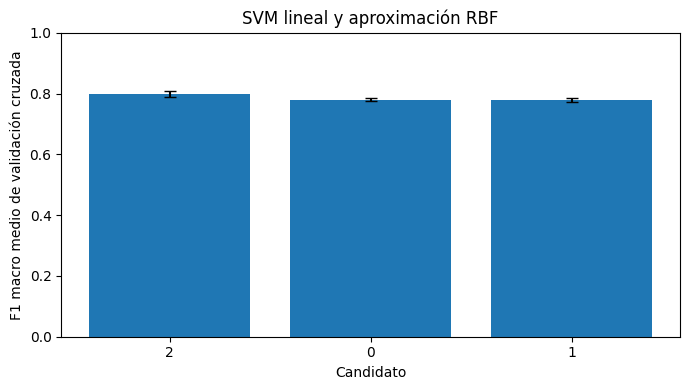

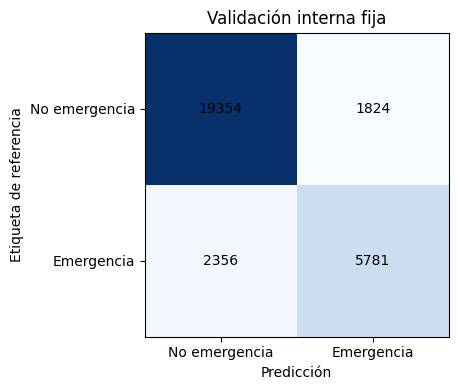

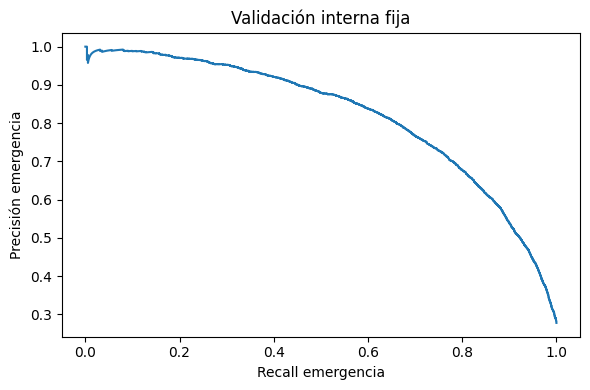

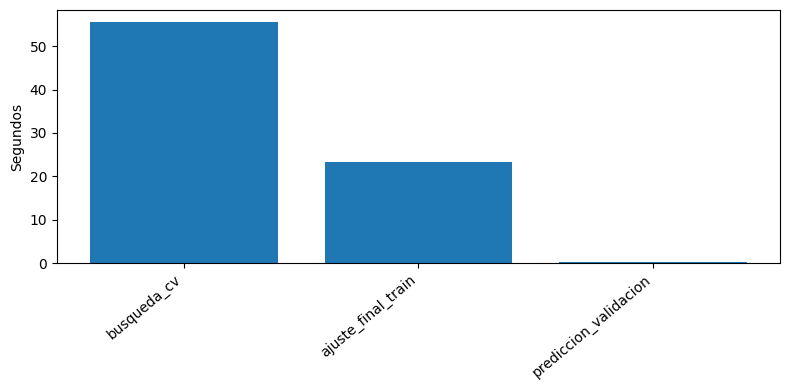

07:32:08 | training_complete | model=03_svm | selected_params={'kernel': 'nystroem_rbf', 'C': 1.0, 'gamma': 0.047619047619047616, 'n_components': 256} | threshold=0.22704


,n,accuracy,precision_emergency,recall_emergency,f1_macro,fpr,roc_auc,average_precision,tn,fp,fn,tp,threshold
0,29315,0.857411,0.760158,0.710458,0.818503,0.086127,0.904343,0.82126,19354,1824,2356,5781,0.227037


RESULTADOS PARA DEVOLVER: /kaggle/working/entrenamiento/03_svm/20261012T072934_078808Z_resultados.zip
MODELOS PARA CONSERVAR: /kaggle/working/entrenamiento/03_svm/20261012T072934_078808Z_modelos.zip
LSSiren: no evaluado. Comparar únicamente ejecuciones con el mismo hash de folds: 3528557381804ea80cf8a9fd230bbe0c37f24e721094162609a2c41f83a2154d
07:32:11 | stage_end | stage=tabular_computation | seconds=26.087


In [54]:
with stage_guard("tabular_computation"):
    for _ in range(CFG["latency_warmup"]):
        scores_of(FINAL, X_VALID[:1])

    latencies = []

    for _ in range(CFG["latency_repeats"]):
        start = time.perf_counter()
        scores_of(FINAL, X_VALID[:1])
        latencies.append((time.perf_counter() - start) * 1000)

    batch = X_VALID[: min(len(X_VALID), CFG["throughput_batch"])]

    start = time.perf_counter()

    scores_of(FINAL, batch)

    batch_seconds = time.perf_counter() - start

    save_table(
        "latency.csv",
        [
            {
                "scope": "CPU; one precomputed feature vector; includes pipeline scaling",
                "warmup": CFG["latency_warmup"],
                "repetitions": len(latencies),
                "p50_ms": np.percentile(latencies, 50),
                "p95_ms": np.percentile(latencies, 95),
                "batch_n": len(batch),
                "batch_seconds": batch_seconds,
                "batch_segments_per_second": len(batch) / batch_seconds,
                "process_peak_rss_mib": resource.getrusage(
                    resource.RUSAGE_SELF
                ).ru_maxrss
                / 1024,
                "model_file_mib": (OUT / "models" / "pipeline.joblib").stat().st_size
                / 1024**2,
            }
        ],
    )

    make_reports(FINAL_SCORES, OOF, THRESHOLD, SELECTED, SUMMARY, runtime_rows)

## Cierre de la ejecución

Comprueba el estado final y conserva los archivos de configuración, particiones, hashes y modelos.
Las tablas y figuras se generan al ejecutar esta notebook; la fuente del repositorio no incluye
resultados antiguos. Las nuevas salidas se revisarán después de su ejecución en Kaggle.
